# Анализ и прогнозирование цен подержанных автомобилей

**Команда № 180**

| Участник | Группа |
|---|---|
| Павчун Дмитрий | 8 |
| Алимова Яна | 11 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from scipy import stats
from scipy.stats import shapiro
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest

## 1. Описание данных

In [2]:
df = pd.read_excel('Автомобили.xlsx')
df.head()

,Производитель,Модель,"Возраст автомобиля, лет","Пробег, миль",Состояние,Тип кузова,Тип топлива,Электромобиль,Коробка передач,Привод,Количество цилиндров,Цвет,"Цена, USD"
0,Ford,super duty f-250 srw,5,118000,Отличное,Грузовик,Дизель,Нет,Автоматическая,Полный,8.0,Черный,43900
1,Chevrolet,silverado 1500,4,133329,Хорошее,Грузовик,Бензин,Нет,Автоматическая,Полный,8.0,Серебристый,26990
2,Ford,thunderbird,18,33970,Отличное,Кабриолет,Бензин,Нет,Автоматическая,Задний,8.0,Красный,18990
3,Ford,f150 platinum 4x4,9,175489,Как новый,Пикап,Бензин,Нет,Автоматическая,Полный,NaN,Черный,14777
4,Tesla,model 3,3,18900,Отличное,Седан,Электричество,Да,Другое,Задний,0.0,Белый,42200


In [3]:
df.shape

(700, 13)

- **Тема:** объявления о продаже подержанных автомобилей в США.
- **Наблюдение:** один автомобиль.
- **Источник:** Used Cars Dataset с Kaggle, из него отобрано 700 машин, названия переведены на русский.
- **Размер:** 700 наблюдений, 13 признаков. Целевая переменная - `Цена, USD`.

## 2. Описание признаков

In [4]:
df.dtypes

Производитель               object
Модель                      object
Возраст автомобиля, лет      int64
Пробег, миль                 int64
Состояние                   object
Тип кузова                  object
Тип топлива                 object
Электромобиль               object
Коробка передач             object
Привод                      object
Количество цилиндров       float64
Цвет                        object
Цена, USD                    int64
dtype: object

| Признак | Описание | Формат | Тип данных |
|---|---|---|---|
| Производитель | марка автомобиля | object | категориальный номинальный |
| Модель | модель автомобиля | object | категориальный номинальный |
| Возраст автомобиля, лет | лет с года выпуска | int64 | количественный дискретный |
| Пробег, миль | пробег по одометру | int64 | количественный непрерывный |
| Состояние | от «Аварийное» до «Новый» | object | категориальный порядковый |
| Тип кузова | седан, внедорожник, пикап и т.д. | object | категориальный номинальный |
| Тип топлива | бензин, дизель, гибрид, электричество, другое | object | категориальный номинальный |
| Электромобиль | Да / Нет | object | категориальный бинарный |
| Коробка передач | автоматическая, механическая, другое | object | категориальный номинальный |
| Привод | передний, задний, полный | object | категориальный номинальный |
| Количество цилиндров | 0 у электромобилей | float64 | количественный дискретный |
| Цвет | цвет кузова | object | категориальный номинальный |
| Цена, USD | цена автомобиля (целевая) | int64 | количественный непрерывный |

У `Количества цилиндров` формат `float64`, потому что в столбце есть пропуски `NaN`.

## 3. Пропуски и дубликаты

In [5]:
df.isna().sum()

Производитель               0
Модель                      0
Возраст автомобиля, лет     0
Пробег, миль                0
Состояние                   0
Тип кузова                  0
Тип топлива                 0
Электромобиль               0
Коробка передач             0
Привод                     40
Количество цилиндров       27
Цвет                       18
Цена, USD                   0
dtype: int64

In [6]:
df.isna().mean() * 100

Производитель              0.000000
Модель                     0.000000
Возраст автомобиля, лет    0.000000
Пробег, миль               0.000000
Состояние                  0.000000
Тип кузова                 0.000000
Тип топлива                0.000000
Электромобиль              0.000000
Коробка передач            0.000000
Привод                     5.714286
Количество цилиндров       3.857143
Цвет                       2.571429
Цена, USD                  0.000000
dtype: float64

In [7]:
df.duplicated().sum()

np.int64(35)

In [8]:
df_clean = df.drop_duplicates().copy()

df_clean['Привод'] = df_clean['Привод'].fillna(df_clean['Привод'].mode()[0])
df_clean['Цвет'] = df_clean['Цвет'].fillna(df_clean['Цвет'].mode()[0])
df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].fillna(df_clean['Количество цилиндров'].median())
df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].astype('int64')

df_clean.shape

(665, 13)

- Пропуски есть в `Привод` (5.7%), `Количество цилиндров` (3.9%) и `Цвет` (2.6%), их мало, поэтому заполняем.
- `Привод` и `Цвет` категориальные - заполняем модой. `Количество цилиндров` - медианой (6), так как среднее 5.59 дробное.
- Удалили 35 полных дубликатов (до заполнения, чтобы они не влияли на моду и медиану).
- В **df_clean** 665 строк без пропусков.

## 4. Выбросы

### 4.1. Ящики с усами

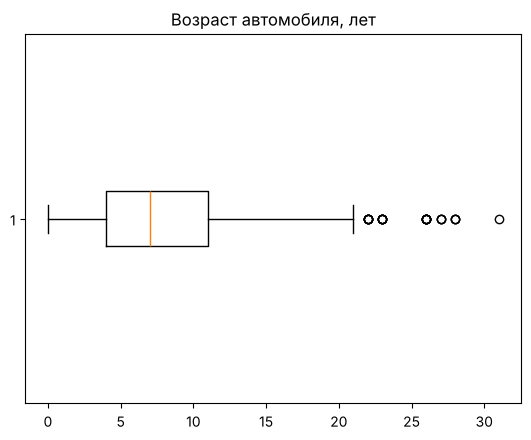

In [9]:
plt.boxplot(df_clean['Возраст автомобиля, лет'], orientation='horizontal')
plt.title('Возраст автомобиля, лет')
plt.show()

Есть выбросы справа: машины старше 21 года.

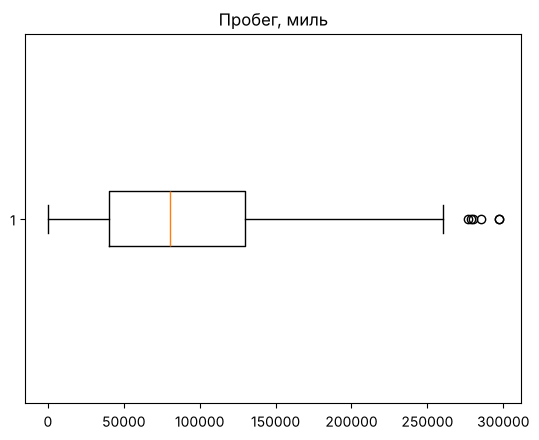

In [10]:
plt.boxplot(df_clean['Пробег, миль'], orientation='horizontal')
plt.title('Пробег, миль')
plt.show()

Несколько выбросов справа: пробег больше 260 тыс. миль.

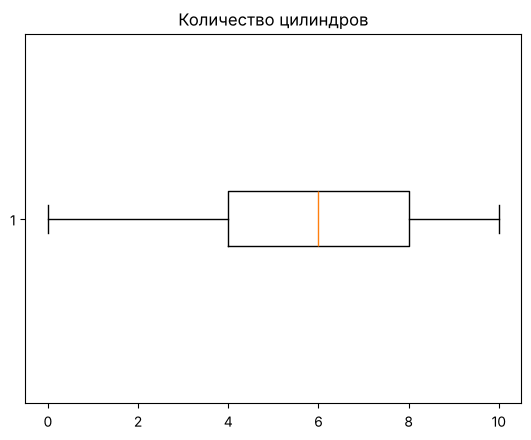

In [11]:
plt.boxplot(df_clean['Количество цилиндров'], orientation='horizontal')
plt.title('Количество цилиндров')
plt.show()

Выбросов нет, все значения от 0 до 10 внутри усов.

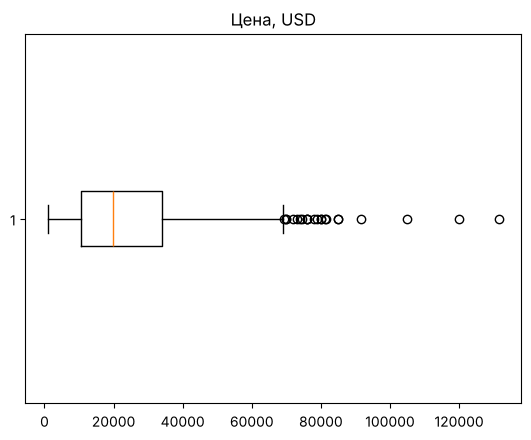

In [12]:
plt.boxplot(df_clean['Цена, USD'], orientation='horizontal')
plt.title('Цена, USD')
plt.show()

Много выбросов справа: машины дороже примерно 70 тыс. USD, максимум 131 500.

### 4.2. Метод N стандартных отклонений

Чистим целевую переменную `Цена, USD`, N = 3

In [13]:
col = df_clean['Цена, USD']
avg = col.mean()
std = col.std()
left = avg - 3 * std
right = avg + 3 * std

df_no_std = df_clean[col.between(left, right)].copy()
print('Границы:', round(left), round(right))
print('Удалено строк:', len(df_clean) - len(df_no_std))

Границы: -31811 80898
Удалено строк: 8


- Удалено 8 машин дороже 80 898 USD. N = 3 взяли, чтобы убрать только самые крайние цены.
- Левая граница отрицательная из-за большого разброса цен, поэтому работает только правая.
- В **df_no_std** 657 строк.

### 4.3. Метод 1.5 * IQR

Чистим предиктор `Пробег, миль` в данных `df_no_std`

In [14]:
col = df_no_std['Пробег, миль']
q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
iqr = q3 - q1
left = q1 - 1.5 * iqr
right = q3 + 1.5 * iqr

df_final = df_no_std[col.between(left, right)].copy()
print('Границы:', left, right)
print('Удалено строк:', len(df_no_std) - len(df_final))

Границы: -88400.0 260976.0
Удалено строк: 6


- Удалено 6 машин с пробегом больше 260 976 миль, левая граница снова отрицательная.
- В **df_final** 651 строка, дальше работаем с ним.

## 5. Визуализация

### 5.1. Гистограммы количественных признаков

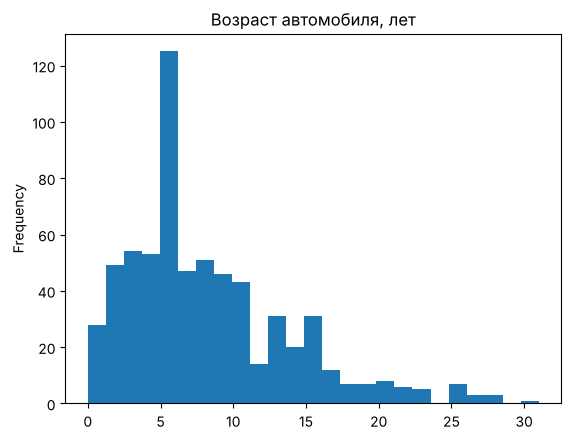

In [15]:
df_final['Возраст автомобиля, лет'].plot(kind='hist', bins=25, title='Возраст автомобиля, лет')
plt.show()

Скошено вправо: в основном машины до 10 лет, отдельные до 31 года.

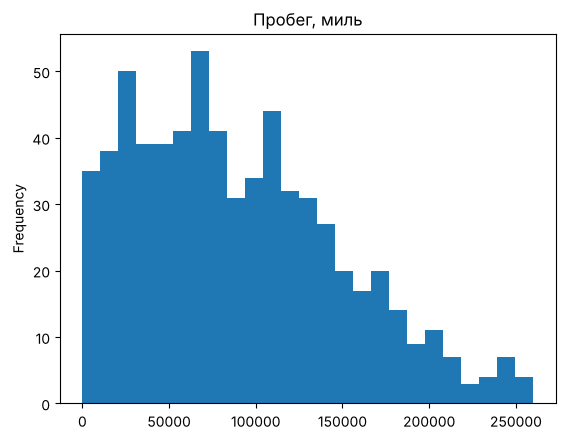

In [16]:
df_final['Пробег, миль'].plot(kind='hist', bins=25, title='Пробег, миль')
plt.show()

Слабая скошенность вправо, чаще всего пробег 40-130 тыс. миль.

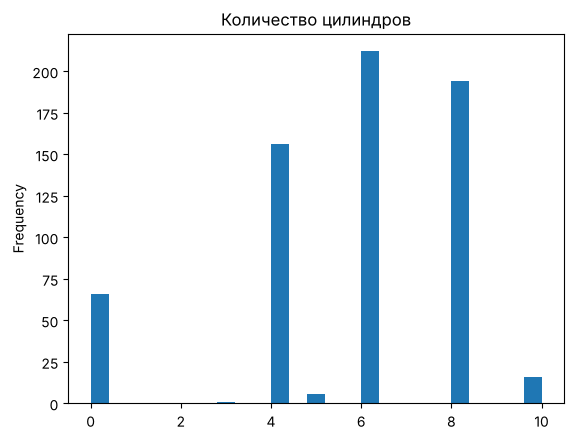

In [17]:
df_final['Количество цилиндров'].plot(kind='hist', bins=25, title='Количество цилиндров')
plt.show()

Дискретный признак: пики на 4, 6 и 8 цилиндрах, отдельно 0 у электромобилей.

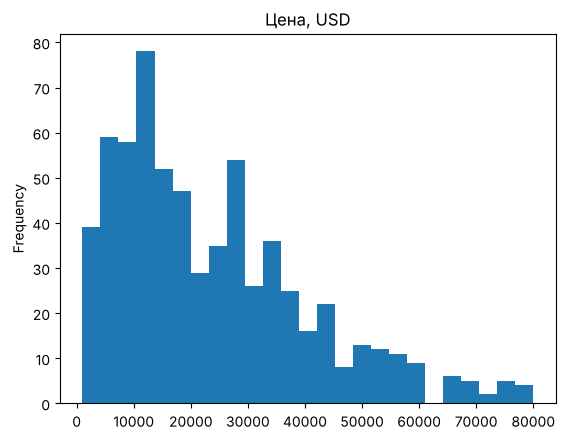

In [18]:
df_final['Цена, USD'].plot(kind='hist', bins=25, title='Цена, USD')
plt.show()

Скошено вправо: большинство машин дешевле 30 тыс. USD, справа хвост дорогих.

In [19]:
df_final[['Возраст автомобиля, лет', 'Пробег, миль', 'Количество цилиндров', 'Цена, USD']].skew()

Возраст автомобиля, лет    1.213955
Пробег, миль               0.602440
Количество цилиндров      -0.838559
Цена, USD                  1.015793
dtype: float64

Коэффициенты асимметрии подтверждают: возраст (1.21), цена (1.02) и пробег (0.60) скошены вправо, у цилиндров асимметрия отрицательная (-0.84) из-за нулей у электромобилей.

### 5.2. Столбчатые диаграммы категориальных признаков

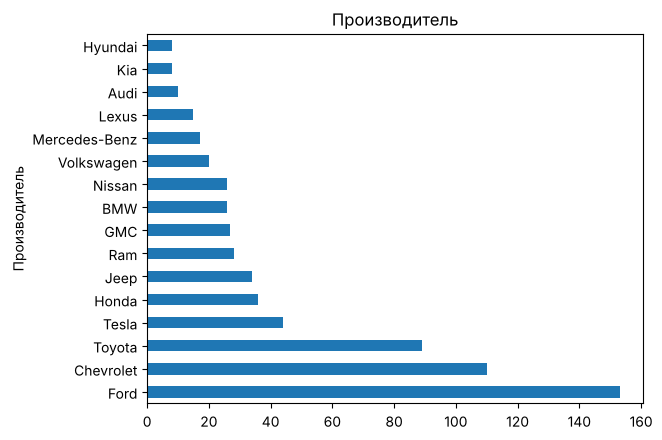

In [20]:
df_final['Производитель'].value_counts().plot(kind='barh', title='Производитель')
plt.show()

Больше всего Ford (153), Chevrolet и Toyota, то есть массовые американские марки.

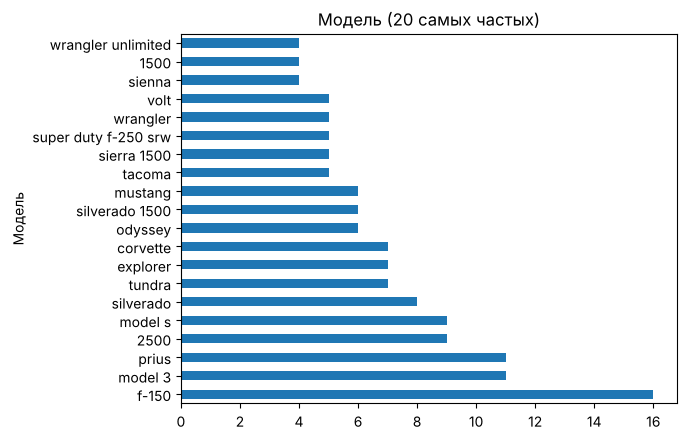

In [21]:
df_final['Модель'].value_counts().head(20).plot(kind='barh', title='Модель (20 самых частых)')
plt.show()

Моделей 444, поэтому показаны 20 самых частых. Даже самая частая f-150 встречается всего 16 раз.

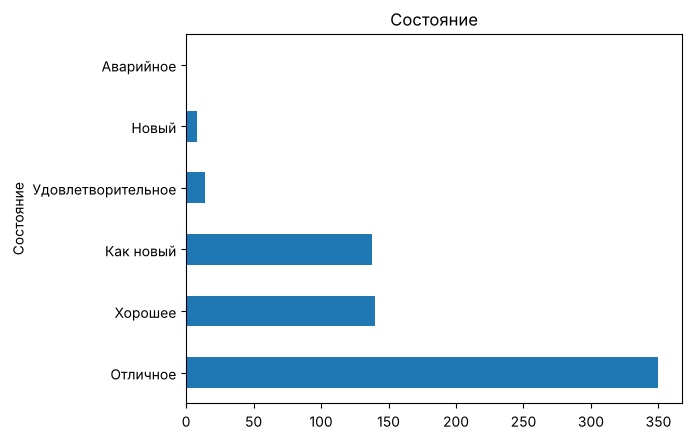

In [22]:
df_final['Состояние'].value_counts().plot(kind='barh', title='Состояние')
plt.show()

Больше половины машин в отличном состоянии, «Новый» и «Аварийное» почти не встречаются.

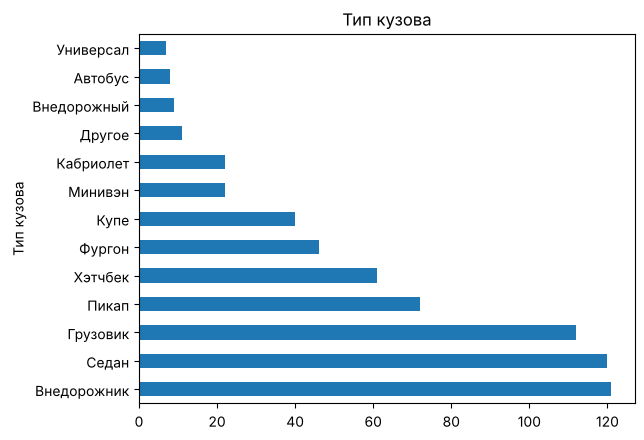

In [23]:
df_final['Тип кузова'].value_counts().plot(kind='barh', title='Тип кузова')
plt.show()

Чаще всего внедорожники, седаны и грузовики, примерно поровну.

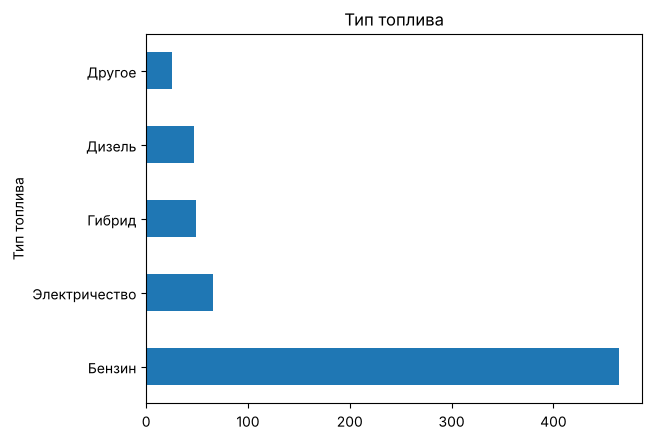

In [24]:
df_final['Тип топлива'].value_counts().plot(kind='barh', title='Тип топлива')
plt.show()

71% машин бензиновые, остальные типы встречаются редко.

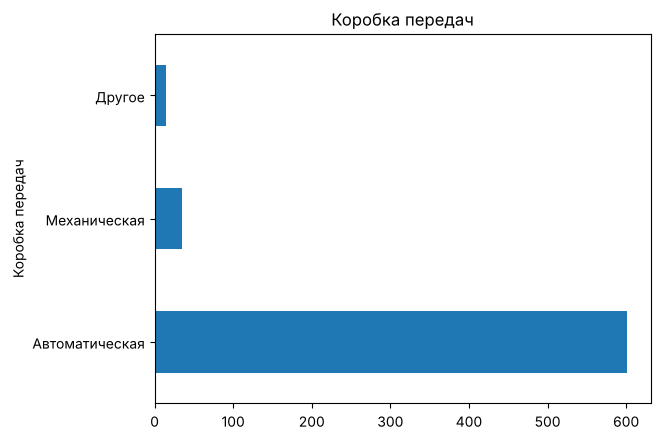

In [25]:
df_final['Коробка передач'].value_counts().plot(kind='barh', title='Коробка передач')
plt.show()

92% машин с автоматом, механика и «другое» редки.

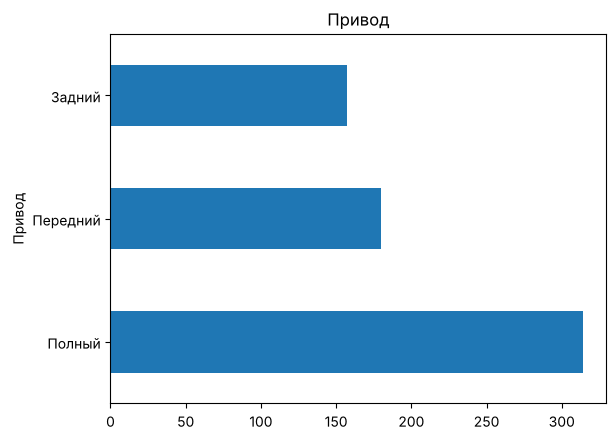

In [26]:
df_final['Привод'].value_counts().plot(kind='barh', title='Привод')
plt.show()

Почти половина машин полноприводные, передний и задний привод встречаются реже.

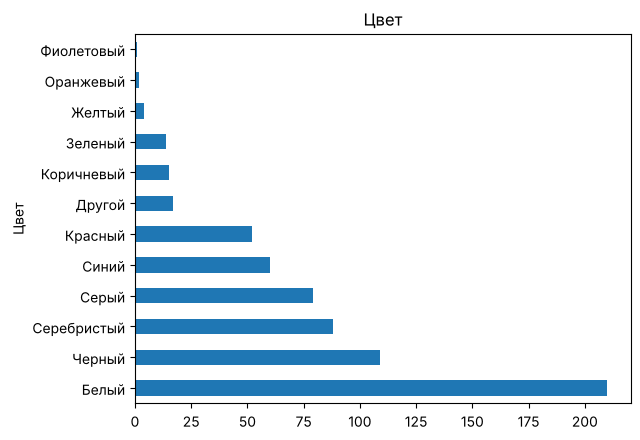

In [27]:
df_final['Цвет'].value_counts().plot(kind='barh', title='Цвет')
plt.show()

Чаще всего белый, чёрный и серебристый цвет.

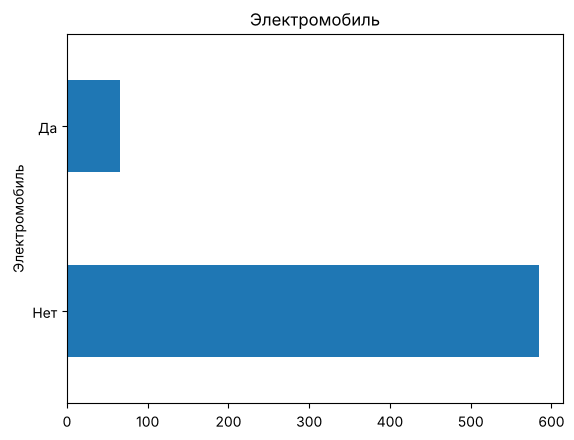

In [28]:
df_final['Электромобиль'].value_counts().plot(kind='barh', title='Электромобиль')
plt.show()

Электромобилей 66 из 651, около 10%.

### 5.3. Скрипичные графики

Возраст и пробег делим на две группы примерно по медиане (7 лет и 80 тыс. миль). `cut=0` не даёт скрипке уходить в отрицательные цены.

In [29]:
df_viol = df_final.copy()
df_viol['Возраст'] = np.where(df_viol['Возраст автомобиля, лет'] <= 7, 'до 7 лет', 'старше 7 лет')
df_viol['Пробег'] = np.where(df_viol['Пробег, миль'] <= 80000, 'до 80 тыс. миль', 'больше 80 тыс. миль')

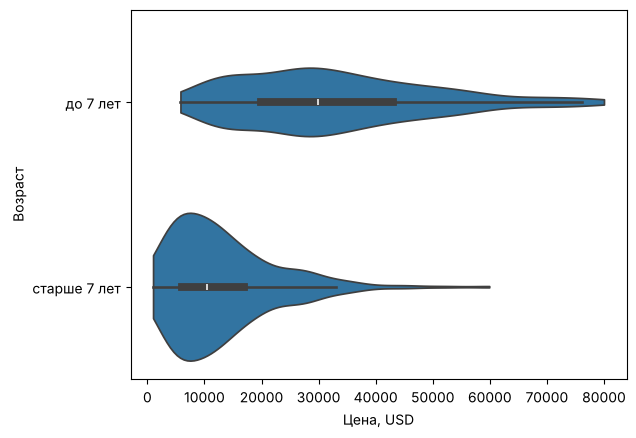

In [30]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Возраст', cut=0)
plt.show()

Машины до 7 лет заметно дороже: медиана около 30 тыс. USD против 10.5 тыс. у старых.

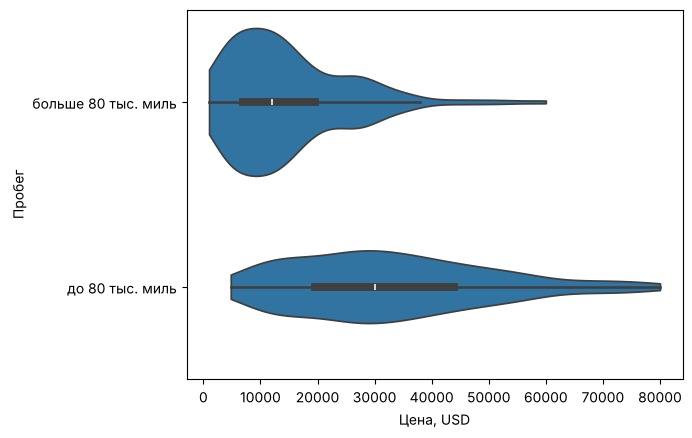

In [31]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Пробег', cut=0)
plt.show()

С пробегом так же: при пробеге до 80 тыс. миль медиана 30 тыс. USD, при большем - 12 тыс.

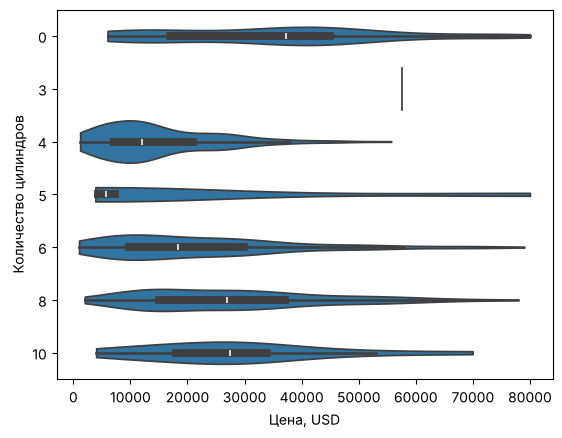

In [32]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Количество цилиндров', orient='h', cut=0)
plt.show()

Без учёта электромобилей (0) цена растёт с числом цилиндров. 3 и 5 цилиндров - единичные машины.

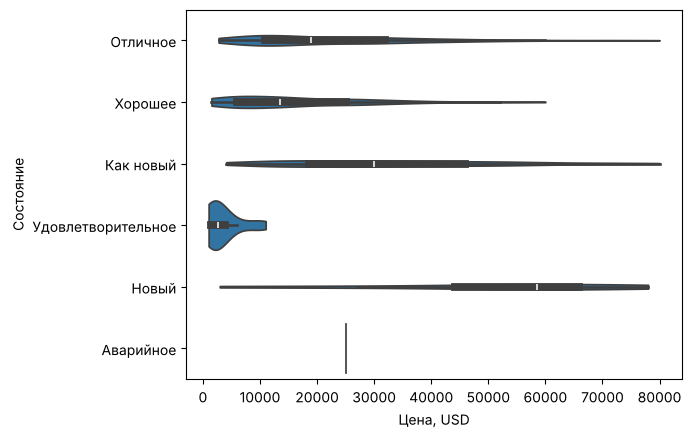

In [33]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Состояние', cut=0)
plt.show()

Чем лучше состояние, тем выше цена. «Аварийное» - одна машина, по ней выводов не делаем.

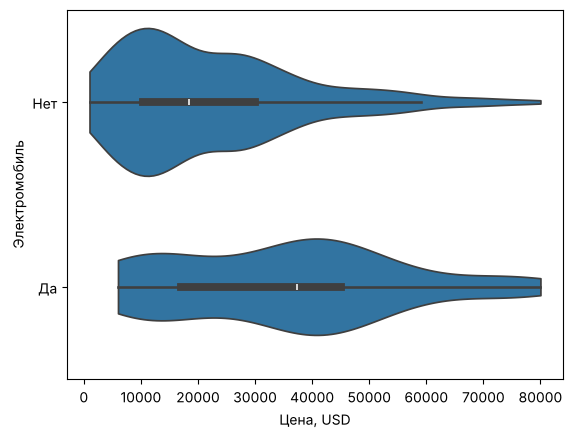

In [34]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Электромобиль', cut=0)
plt.show()

Электромобили примерно вдвое дороже: медиана 37 281.5 против 18 500 USD.

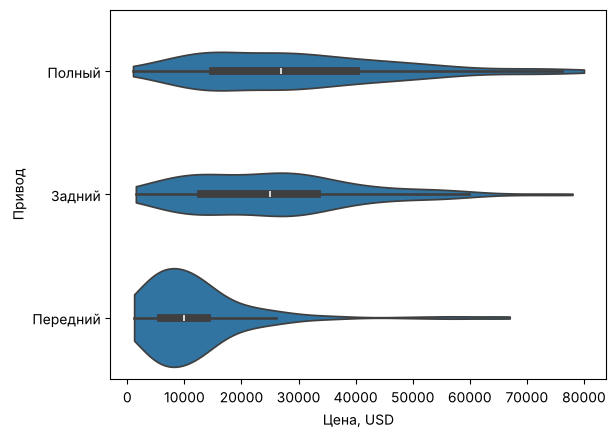

In [35]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Привод', cut=0)
plt.show()

Переднеприводные машины заметно дешевле (медиана около 10 тыс.), полный и задний привод близки.

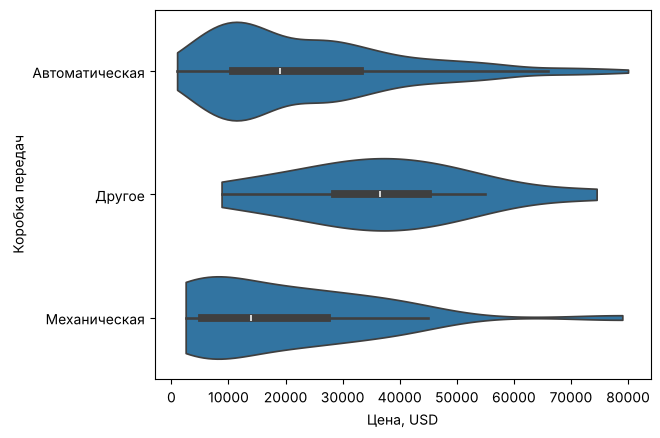

In [36]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Коробка передач', cut=0)
plt.show()

У автомата и механики распределения похожи. Дорогая группа «другое» - всего 15 машин.

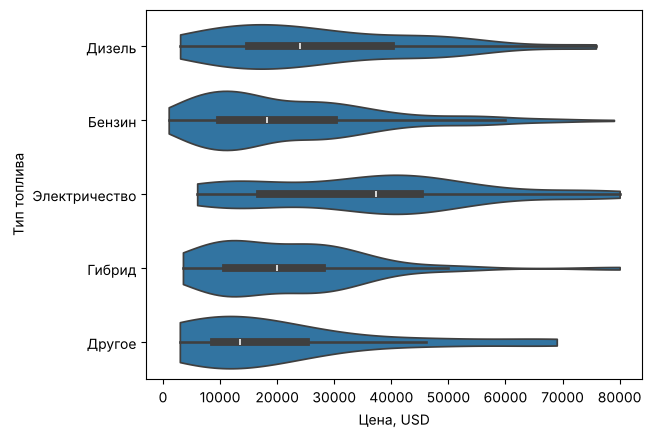

In [37]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Тип топлива', cut=0)
plt.show()

Дороже всего электромобили, дешевле всего бензин и «другое».

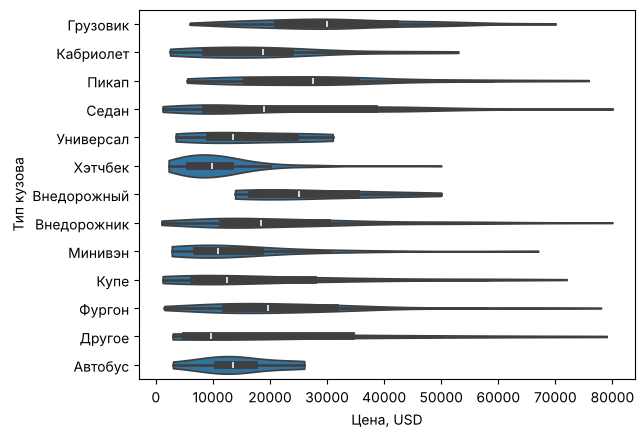

In [38]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Тип кузова', cut=0)
plt.show()

Дороже всего грузовики и пикапы, дешевле хэтчбеки и минивэны.

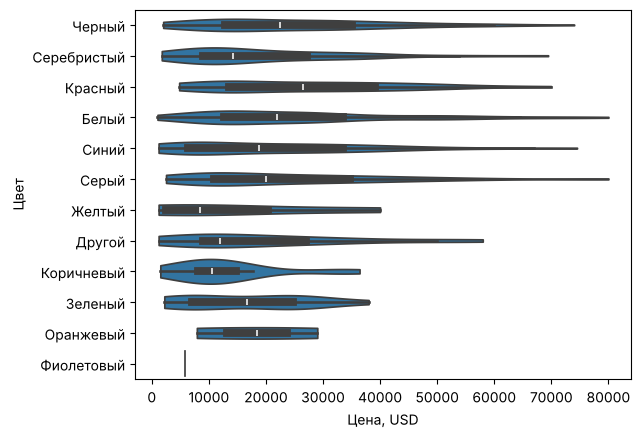

In [39]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Цвет', cut=0)
plt.show()

У распространённых цветов распределения похожи, явной связи цвета с ценой нет.

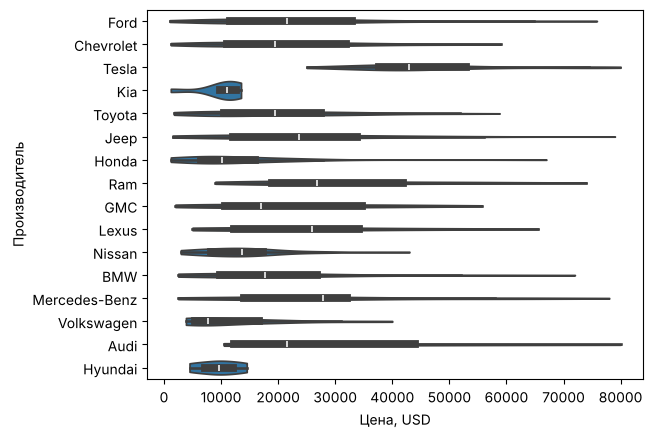

In [40]:
sns.violinplot(data=df_viol, x='Цена, USD', y='Производитель', cut=0)
plt.show()

Выделяется Tesla, у неё цены выше остальных. Дешевле всего Volkswagen и Hyundai.

Медианная цена по группам для проверки выводов

In [41]:
for col in ['Возраст', 'Пробег', 'Состояние', 'Электромобиль', 'Привод']:
    print(df_viol.groupby(col)['Цена, USD'].median(), '\n')

Возраст
до 7 лет        29925.0
старше 7 лет    10500.0
Name: Цена, USD, dtype: float64 

Пробег
больше 80 тыс. миль    11992.5
до 80 тыс. миль        30000.0
Name: Цена, USD, dtype: float64 

Состояние
Аварийное             25000.0
Как новый             29939.0
Новый                 58491.0
Отличное              18994.5
Удовлетворительное     2600.0
Хорошее               13500.0
Name: Цена, USD, dtype: float64 

Электромобиль
Да     37281.5
Нет    18500.0
Name: Цена, USD, dtype: float64 

Привод
Задний      25000.0
Передний     9996.0
Полный      26999.5
Name: Цена, USD, dtype: float64 



`Модель` скрипичным графиком не показываем: у неё 444 категории, в большинстве по 1-2 машины. В целом сильнее всего с ценой связаны возраст, пробег, состояние, привод и признак электромобиля.

## 6. Описательные статистики

### 6.1. Целевая переменная

In [42]:
df_final['Цена, USD'].describe()

count      651.000000
mean     23767.130568
std      16952.077999
min       1000.000000
25%      10500.000000
50%      19500.000000
75%      33500.000000
max      80000.000000
Name: Цена, USD, dtype: float64

In [43]:
price = df_final['Цена, USD']
print('Мода:', price.mode()[0])
print('Размах:', price.max() - price.min())
print('IQR:', price.quantile(0.75) - price.quantile(0.25))
print('Дисперсия:', round(price.var()))

Мода: 11500
Размах: 79000
IQR: 23000.0
Дисперсия: 287372948


- **Медиана** 19 500 USD - половина машин дешевле. Это типичная цена.
- **Среднее** 23 767 USD выше медианы из-за дорогих машин.
- **Мода** 11 500 USD - самая частая цена.
- **Минимум** 1 000, **максимум** 80 000, **размах** 79 000 USD.
- Центральные 50% цен лежат от 10 500 до 33 500 USD, **IQR** = 23 000.
- **Стандартное отклонение** 16 952 USD - разброс цен большой.
- **Дисперсия** 287 372 948 в квадратах долларов, отдельно не интерпретируется.

### 6.2. Предикторы

In [44]:
df_final[['Возраст автомобиля, лет', 'Пробег, миль', 'Количество цилиндров']].describe()

,"Возраст автомобиля, лет","Пробег, миль",Количество цилиндров
count,651.000000,651.000000,651.000000
mean,8.244240,89815.984639,5.592934
std,5.696175,58968.601773,2.461747
min,0.000000,10.000000,0.000000
25%,4.000000,42000.000000,4.000000
50%,7.000000,80384.000000,6.000000
75%,11.000000,129345.500000,8.000000
max,31.000000,260000.000000,10.000000


In [45]:
df_final.describe(include=object)

,Производитель,Модель,Состояние,Тип кузова,Тип топлива,Электромобиль,Коробка передач,Привод,Цвет
count,651,651,651,651,651,651,651,651,651
unique,16,444,6,13,5,2,3,3,12
top,Ford,f-150,Отличное,Внедорожник,Бензин,Нет,Автоматическая,Полный,Белый
freq,153,16,350,121,464,585,601,314,210


- **Возраст:** медиана 7 лет, половина машин от 4 до 11 лет, среднее 8.2, максимум 31.
- **Пробег:** медиана 80 384 мили, половина машин от 42 000 до 129 346, std 58 969.
- **Количество цилиндров:** медиана 6, квартили 4 и 8.
- **Категориальные** (мода и число значений): производитель - Ford (16 марок), модель - f-150 (444), состояние - «Отличное» (6), кузов - «Внедорожник» (13), топливо - «Бензин» (5), электромобиль - «Нет» (2), коробка - «Автоматическая» (3), привод - «Полный» (3), цвет - «Белый» (12).

## 7. Перекодирование данных

### 7.1. One-Hot кодирование

In [46]:
df_encoded = pd.get_dummies(df_final, columns=['Электромобиль', 'Привод'], dtype=int)
df_encoded[['Электромобиль_Да', 'Электромобиль_Нет', 'Привод_Задний', 'Привод_Передний', 'Привод_Полный']].head()

,Электромобиль_Да,Электромобиль_Нет,Привод_Задний,Привод_Передний,Привод_Полный
0,0,1,0,0,1
1,0,1,0,0,1
2,0,1,1,0,0
3,0,1,0,0,1
4,1,0,1,0,0


Бинарный `Электромобиль` превратился в столбцы 0/1. Привод тоже закодировали One-Hot, он понадобится в регрессии.

### 7.2. LabelEncoder

In [47]:
df_encoded['Коробка_encoded'] = LabelEncoder().fit_transform(df_encoded['Коробка передач'])
df_encoded[['Коробка передач', 'Коробка_encoded']].drop_duplicates()

,Коробка передач,Коробка_encoded
0,Автоматическая,0
4,Другое,1
29,Механическая,2


Коды присвоены по алфавиту и порядка не означают, поэтому дальше этот столбец не используем.

### 7.3. OrdinalEncoder

In [48]:
order = [['Аварийное', 'Удовлетворительное', 'Хорошее', 'Отличное', 'Как новый', 'Новый']]
df_encoded['Состояние_encoded'] = OrdinalEncoder(categories=order).fit_transform(df_encoded[['Состояние']])
df_encoded[['Состояние', 'Состояние_encoded']].drop_duplicates().sort_values('Состояние_encoded')

,Состояние,Состояние_encoded
698,Аварийное,0.0
15,Удовлетворительное,1.0
1,Хорошее,2.0
0,Отличное,3.0
3,Как новый,4.0
115,Новый,5.0


Состояние закодировано по порядку от 0 («Аварийное») до 5 («Новый»).

## 8. Корреляционный анализ

### 8.1. Парная корреляция цены и пробега

In [49]:
df_encoded['Цена, USD'].corr(df_encoded['Пробег, миль'])

np.float64(-0.5985874849243735)

In [50]:
df_encoded['Цена, USD'].corr(df_encoded['Пробег, миль'], method='spearman')

np.float64(-0.6418839772063827)

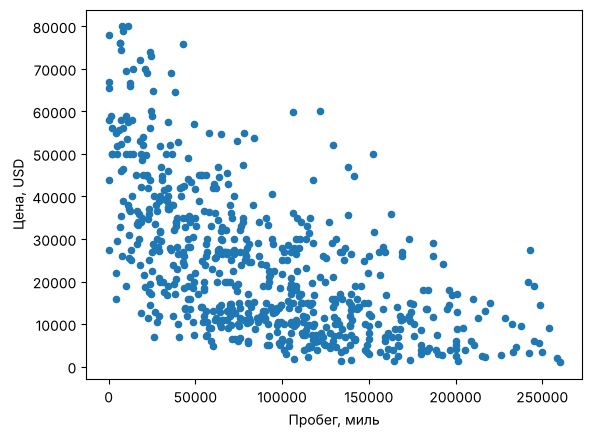

In [51]:
df_encoded.plot('Пробег, миль', 'Цена, USD', kind='scatter')
plt.show()

- Пирсон -0.60: умеренная, близкая к сильной, обратная линейная связь. Чем больше пробег, тем ниже цена.
- Спирмен -0.64 чуть больше по модулю, значит связь скорее нелинейная.
- Корреляция не означает, что пробег является причиной низкой цены.

### 8.2. Корреляционная матрица

В матрице есть порядковый и бинарные признаки, поэтому используем Спирмена (Пирсон - только для количественных).

In [52]:
corr_cols = ['Цена, USD', 'Пробег, миль', 'Возраст автомобиля, лет', 'Количество цилиндров',
             'Состояние_encoded', 'Электромобиль_Да', 'Привод_Задний', 'Привод_Передний', 'Привод_Полный']

cm = df_encoded[corr_cols].corr(method='spearman').round(2)
cm

,"Цена, USD","Пробег, миль","Возраст автомобиля, лет",Количество цилиндров,Состояние_encoded,Электромобиль_Да,Привод_Задний,Привод_Передний,Привод_Полный
"Цена, USD",1.00,-0.64,-0.69,0.16,0.39,0.20,0.09,-0.49,0.36
"Пробег, миль",-0.64,1.00,0.69,0.19,-0.47,-0.26,-0.07,0.09,-0.02
"Возраст автомобиля, лет",-0.69,0.69,1.00,0.15,-0.44,-0.18,0.09,0.13,-0.19
Количество цилиндров,0.16,0.19,0.15,1.00,-0.14,-0.54,0.27,-0.44,0.16
Состояние_encoded,0.39,-0.47,-0.44,-0.14,1.00,0.12,-0.07,-0.04,0.10
Электромобиль_Да,0.20,-0.26,-0.18,-0.54,0.12,1.00,0.01,0.02,-0.03
Привод_Задний,0.09,-0.07,0.09,0.27,-0.07,0.01,1.00,-0.35,-0.54
Привод_Передний,-0.49,0.09,0.13,-0.44,-0.04,0.02,-0.35,1.00,-0.60
Привод_Полный,0.36,-0.02,-0.19,0.16,0.10,-0.03,-0.54,-0.60,1.00


### 8.3. Топ-5 признаков

In [53]:
cm['Цена, USD'].sort_values(key=abs, ascending=False)

Цена, USD                  1.00
Возраст автомобиля, лет   -0.69
Пробег, миль              -0.64
Привод_Передний           -0.49
Состояние_encoded          0.39
Привод_Полный              0.36
Электромобиль_Да           0.20
Количество цилиндров       0.16
Привод_Задний              0.09
Name: Цена, USD, dtype: float64

Первая строка - сама цена. Топ-5:

1. Возраст (-0.69) - умеренная, близкая к сильной, обратная связь.
2. Пробег (-0.64) - умеренная, близкая к сильной, обратная связь.
3. Передний привод (-0.49) - умеренная обратная связь.
4. Состояние (0.39) - умеренная прямая связь.
5. Полный привод (0.36) - умеренная прямая связь.

Между собой связаны возраст и пробег (0.69), цилиндры и электромобиль (-0.54).

## 9. Масштабирование данных

In [54]:
quant_cols = ['Пробег, миль', 'Возраст автомобиля, лет', 'Количество цилиндров']

df_scaled = df_encoded.copy()
df_scaled[quant_cols] = StandardScaler().fit_transform(df_scaled[quant_cols])
df_scaled[quant_cols].describe().round(2)

,"Пробег, миль","Возраст автомобиля, лет",Количество цилиндров
count,651.00,651.00,651.00
mean,0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.52,-1.45,-2.27
25%,-0.81,-0.75,-0.65
50%,-0.16,-0.22,0.17
75%,0.67,0.48,0.98
max,2.89,4.00,1.79


После `StandardScaler` у количественных признаков среднее 0 и стандартное отклонение 1. Так коэффициенты пробега и возраста можно сравнивать между собой. Цену и категории не масштабируем.

## 10. Линейная регрессия

### 10.1. Описание модели

Мы хотим построить модель, которая предсказывает цену подержанного автомобиля по пробегу, возрасту, состоянию, приводу и тому, является ли он электромобилем.

- Берём топ-5 признаков и `Электромобиль_Да`.
- `Привод_Задний` не берём - это базовая категория для двух других столбцов привода.
- `Количество цилиндров` не берём: с ценой связано слабо (0.16), а с электромобилем заметно (-0.54).
- 6 предикторов на 651 наблюдение, больше 100 на предиктор.

### 10.2. Деление выборки

In [55]:
X = df_scaled[['Пробег, миль', 'Возраст автомобиля, лет', 'Состояние_encoded',
               'Электромобиль_Да', 'Привод_Передний', 'Привод_Полный']]
Y = df_scaled['Цена, USD']

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((520, 6), (131, 6))

520 машин для обучения и 131 для проверки, `random_state=42` фиксирует разбиение.

### 10.3. Обучение модели

In [56]:
model = LinearRegression().fit(X_train, y_train)
model.intercept_

np.float64(19722.850462697676)

In [57]:
model.coef_

array([ -5755.63752165,  -5118.15310861,   1958.14509302,   5368.1648777 ,
       -12290.68913446,   2031.34140164])

$$\text{Цена} = 19722.85 - 5755.64 \cdot \text{Пробег} - 5118.15 \cdot \text{Возраст} + 1958.15 \cdot \text{Состояние} + 5368.16 \cdot \text{Электромобиль} - 12290.69 \cdot \text{Передний} + 2031.34 \cdot \text{Полный}$$

### 10.4. Интерпретация параметров

При прочих равных:

- **$w_0$ = 19 722.85:** цена машины со средним пробегом и возрастом, в аварийном состоянии, не электромобиля, с задним приводом. Такой машины почти нет, поэтому коэффициент условный.
- **Пробег (-5 755.64):** пробег больше на одно стандартное отклонение (59 тыс. миль) - цена ниже на 5 756 USD.
- **Возраст (-5 118.15):** возраст больше на одно стандартное отклонение (5.7 года) - цена ниже на 5 118 USD.
- **Состояние (1 958.15):** состояние лучше на одну ступень - цена выше на 1 958 USD.
- **Электромобиль (5 368.16):** электромобиль дороже на 5 368 USD.
- **Передний привод (-12 290.69):** дешевле на 12 291 USD, чем задний.
- **Полный привод (2 031.34):** дороже на 2 031 USD, чем задний.

### 10.5. Метрики качества

In [58]:
y_pred = model.predict(X_test)

print('R2 =', r2_score(y_test, y_pred))
print('MSE =', mean_squared_error(y_test, y_pred))
print('MAE =', mean_absolute_error(y_test, y_pred))

R2 = 0.6134900112059258
MSE = 103084860.60380927
MAE = 8110.012274589738


- **$R^2$ = 0.61:** модель объясняет 61% разброса цен, 39% остались не описаны.
- **MAE = 8 110:** в среднем модель ошибается на 8 110 USD, это примерно треть средней цены.
- **MSE = 103 084 861:** в квадратах долларов, используется только для сравнения моделей.
- Знаки коэффициентов логичны, но для точного прогноза не хватает марки и модели машины.

## 11. Тестирование гипотез

Выводы делаем на уровнях 1%, 5% и 10%: если p-value меньше уровня, $H_0$ отвергается.

### 11.1. Тест Шапиро-Уилка

Проверим, распределены ли нормально цена, пробег и возраст.

$H_0: X \sim N(\mu, \sigma^2)$

$H_1: X \nsim N(\mu, \sigma^2)$

In [59]:
print(shapiro(df_final['Цена, USD'])[1])
print(shapiro(df_final['Пробег, миль'])[1])
print(shapiro(df_final['Возраст автомобиля, лет'])[1])

1.159062202201416e-18
1.352414904423235e-12
5.698633992382696e-20


Все p-value меньше 0.01, $H_0$ отвергается: признаки не нормальны. Выборка большая, поэтому в z- и t-тестах, как в кейсах лекции, **будем считать признак нормально распределённым**.

### 11.2. Z-тест

Мы хотим проверить гипотезу о том, что средняя цена равна 25 000 USD, если считать, что выборочная дисперсия равна дисперсии генеральной совокупности.

$H_0: \mu_{цена} = 25000$

$H_1: \mu_{цена} \neq 25000$

In [60]:
ztest(df_final['Цена, USD'], value=25000, alternative='two-sided')

(np.float64(-1.8556011668650885), np.float64(0.06351042725572026))

p-value = 0.0635: на 1% и 5% $H_0$ не отвергается, на 10% отвергается. На уровне 5% нельзя сказать, что средняя цена отличается от 25 000 USD.

### 11.3. Одновыборочный t-тест

Мы хотим проверить гипотезу о том, что средняя цена больше 22 000 USD.

$H_0: \mu_{цена} = 22000$

$H_1: \mu_{цена} > 22000$

In [61]:
stats.ttest_1samp(df_final['Цена, USD'], popmean=22000, alternative='greater')

TtestResult(statistic=np.float64(2.659721670828892), pvalue=np.float64(0.0040066568788041405), df=np.int64(650))

p-value = 0.004 < 0.01: $H_0$ отвергается на всех уровнях, средняя цена больше 22 000 USD.

### 11.4. Парный t-тест

Парный t-тест сравнивает два измерения одних и тех же объектов, например цену машины до и после ремонта.

$H_0: \mu_{до} = \mu_{после}$

$H_1: \mu_{до} < \mu_{после}$

Провести его нельзя: каждая машина в данных встречается один раз, связанных выборок нет.

### 11.5. Двухвыборочный t-тест

Мы хотим проверить гипотезу о том, что средняя цена машин с автоматом равна средней цене машин с механикой.

$H_0: \mu_{автомат} = \mu_{механика}$

$H_1: \mu_{автомат} \neq \mu_{механика}$

In [62]:
auto = df_final[df_final['Коробка передач'] == 'Автоматическая']['Цена, USD']
mech = df_final[df_final['Коробка передач'] == 'Механическая']['Цена, USD']
auto.std(), mech.std()

(np.float64(16829.599425962035), np.float64(16780.34808985817))

In [63]:
stats.ttest_ind(auto, mech, alternative='two-sided')

TtestResult(statistic=np.float64(1.4926875120502463), pvalue=np.float64(0.13601644353955847), df=np.float64(634.0))

Выборки не связаны, стандартные отклонения почти равны (16 830 и 16 780), значит дисперсии можно считать равными. p-value = 0.136: $H_0$ не отвергается ни на одном уровне, разница средних цен не значима.

### 11.6. Тест Манна-Уитни

Мы хотим проверить, отличается ли уровень цен машин с полным и задним приводом.

$H_0$: уровень цен при полном и заднем приводе не отличается

$H_1$: уровень цен при полном и заднем приводе отличается

In [64]:
full_drive = df_final[df_final['Привод'] == 'Полный']['Цена, USD']
rear_drive = df_final[df_final['Привод'] == 'Задний']['Цена, USD']
full_drive.skew(), rear_drive.skew()

(np.float64(0.7538611977029978), np.float64(0.7662519390100376))

In [65]:
stats.mannwhitneyu(full_drive, rear_drive, alternative='two-sided')

MannwhitneyuResult(statistic=np.float64(28023.5), pvalue=np.float64(0.015392660349809541))

Выборки не связаны, форма распределений схожа (асимметрия 0.75 и 0.77). p-value = 0.015: на 5% и 10% $H_0$ отвергается, полноприводные машины дороже. На 1% не отвергается.

### 11.7. Z-тест для пропорций

Мы хотим проверить, одинакова ли доля электромобилей среди дорогих (дороже медианы 19 500 USD) и дешёвых машин.

$H_0: p_{дорогие} = p_{дешёвые}$

$H_1: p_{дорогие} \neq p_{дешёвые}$

In [66]:
df_encoded['Сегмент'] = np.where(df_encoded['Цена, USD'] > 19500, 'дорогие', 'дешёвые')
gb = df_encoded.groupby('Сегмент')['Электромобиль_Да'].agg(['sum', 'count'])
gb

,sum,count
Сегмент,,
дешёвые,19,328
дорогие,47,323


In [67]:
proportions_ztest(gb['sum'], gb['count'], alternative='two-sided')

(np.float64(-3.701720168524791), np.float64(0.00021414272110861622))

Выборки не связаны, признак бинарный. p-value = 0.0002: $H_0$ отвергается на всех уровнях. Среди дорогих машин электромобилей 14.6%, среди дешёвых 5.8%.

### 11.8. Хи-квадрат

Мы хотим проверить, связан ли тип привода с тем, является ли машина электромобилем.

$H_0$: привод и электромобиль не связаны

$H_1$: привод и электромобиль связаны

In [68]:
gb = df_final[['Электромобиль', 'Привод']].value_counts().unstack()
gb

Привод,Задний,Передний,Полный
Электромобиль,,,
Да,17,20,29
Нет,140,160,285


In [69]:
stats.chi2_contingency(gb.values)

Chi2ContingencyResult(statistic=np.float64(0.5497697042283034), pvalue=np.float64(0.7596595913848974), dof=2, expected_freq=array([[ 15.91705069,  18.24884793,  31.83410138],
       [141.08294931, 161.75115207, 282.16589862]]))

В каждой группе не меньше 5 машин (у других пар признаков это не выполняется). p-value = 0.76: $H_0$ не отвергается, доля электромобилей при любом приводе примерно одинаковая.

## 12. Общие выводы

- После чистки осталось 651 машина из 700, цены скошены вправо, типичная цена 19 500 USD.
- Сильнее всего с ценой связаны возраст и пробег, а также привод и состояние.
- Регрессия объясняет 61% разброса цен и ошибается в среднем на 8 110 USD.
- Средняя цена больше 22 000 USD, полноприводные машины дороже заднеприводных, а электромобили чаще среди дорогих машин.